# xQML Test2

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import healpy as hp
import os
import camb
from camb import model, initialpower
from scipy.optimize import minimize
from corner import corner
from minkasi.null_test.estimators import polspice
from minkasi import util as mt
import xqml

pars = camb.CAMBparams()

In [2]:
lmax=22
nside = 8

# get power spectra for a given tau
def get_Clhat(tau, lmax=lmax, raw_cl=True,
              H0=67, Ombh2=0.024, Omch2=0.12,
              As=2.1e-9, ns=0.965, ks=0.05, 
              kt=0.05, Omk=0, TCMB=2.7255, 
              mnu=0.06, r=0, YHe=0.245400,):
    '''
    Specify tau, and use other known parameters
    '''
    pars.set_cosmology(H0=H0, ombh2=Ombh2, omch2=Omch2, mnu=mnu, omk=Omk, tau=tau, TCMB=TCMB, YHe=YHe)
    pars.InitPower.set_params(As=As, ns=ns, r=r, pivot_scalar=ks, pivot_tensor=kt)
    results = camb.get_results(pars)
    powers = results.get_total_cls(lmax=lmax, CMB_unit='muK', raw_cl=True)
    TT, EE, BB, TE = powers.T
    #ls = np.arange(2, EE.shape[0]) # could add??
    return np.array([TT, EE, BB, TE])

true_tau = 0.054
ls = np.arange(2, lmax+1)
true_spectra = get_Clhat(true_tau) # ensemble average power spectrum
Z = ls*(ls+1)/(2*np.pi)
# plt.semilogx(ls, true_spectra[1][ls]*Z)
# plt.xlabel(r'$\ell$')
# plt.ylabel(r'$\frac{\ell(\ell+1)}{2\pi}C_\ell$\,$\mathrm{[\mu K^2]}$')
# plt.title("True CMB EE Spectrum")


In [3]:
grid_min = 0
grid_max = 0.15
grid_size = 500

tau_coarse_grid = np.linspace(grid_min, grid_max, 100)

EE_coarse_grid = np.array([
    get_Clhat(t)[1]
    for t in tau_coarse_grid
])

from scipy.interpolate import CubicSpline
EE_cubicspline = CubicSpline(
    tau_coarse_grid, 
    EE_coarse_grid, 
    axis=0
)

tau_grid = np.linspace(grid_min, grid_max, grid_size)

EE_grid = EE_cubicspline(tau_grid)

 Check input parameters an Reionization_xe
 function in the Reionization module


In [6]:
#ell = np.arange(2, lmax)
DELL = 3
bins = xqml.Bins.fromdeltal(2,lmax,DELL)
ell_xqml = np.arange(2, lmax+1)
ell_bins_xqml = bins.lbin
ell_index_xqml = np.array([np.where(ls == L)[0][0] for L in ell_xqml])
# EE_grid_full_xqml = np.zeros((len(tau_grid), lmax + 1))
# EE_grid_full_xqml[:, ell_xqml] = EE_grid[:, ell_index_xqml]
EE_grid_binned_xqml = bins.bin_spectra(EE_grid, Dl=True)

EE_input_xqml = np.array(true_spectra[1][:lmax + 1], copy=True)
EE_input_xqml[ell_xqml] = EE_cubicspline(0.054)[ell_xqml]
clth_xqml = np.array([
    true_spectra[0][:lmax + 1],
    EE_input_xqml,
    true_spectra[2][:lmax + 1],
    true_spectra[3][:lmax + 1]])

In [7]:
print(EE_grid[0][2:9])

[3.13345804e-06 4.82545659e-06 6.95841381e-06 9.50755595e-06
 1.24478974e-05 1.57612014e-05 1.94256243e-05]


In [8]:
print(EE_grid_binned_xqml[0][:2])

[4.97244281e-06 1.25722182e-05]


In [9]:
def full_sky_wishart(noise, nsim, ver = 2):
    taus = []
    
    # NOISE CALCS
    npix = hp.nside2npix(nside)
    solid_angle = hp.nside2pixarea(nside)
    # map sensitivity
    sigma_pix = noise * (np.pi / 180 / 60)/ np.sqrt(solid_angle)
    Nl = 4*np.pi * sigma_pix**2 / npix

    # masking
    temp_mask = np.ones(npix, dtype=bool)

    NoiseVar = (sigma_pix**2 * np.eye(2*npix))

    spec = ['EE','BB']

    esti = xqml.xQML(
        temp_mask,
        temp_mask,
        bins,
        clth_xqml,
        NA=NoiseVar,
        NB=NoiseVar,
        lmax=lmax,
        fwhm=0,
        spec=spec,
        pixwin=False
    )

    var_grid_cross = np.array([
        (1/(2*ell_bins_xqml + 1)) *
        (ee**2 + (ee + Nl)**2)
        for ee in EE_grid_binned_xqml
    ])

    log_var_cross = np.log(2*np.pi*var_grid_cross)

    covariance_full = esti.get_covariance() 
    covariance_EE = covariance_full[0:len(ell_bins_xqml), 0:len(ell_bins_xqml)]
    icovariance_EE = np.linalg.inv(covariance_EE)

    for i in range(nsim):
        s1 = hp.synfast(true_spectra, nside, lmax=lmax, new=True, pol=True)

        n1 = np.random.randn(npix) * sigma_pix
        n2 = np.random.randn(npix) * sigma_pix 

        map1 = s1[1:3] + n1
        map2 = s1[1:3] + n2

        Clhat_cross = esti.get_spectra(map1, map2)[0]

        if ver == 1: # wishart
            x = ((Clhat_cross[None, :])/(EE_grid_binned_xqml))
            x = np.maximum(x, 1e-10)
            chi2_cross = np.sum(
                (2*ell_bins_xqml+1)*(x - np.log(x) - 1),
                axis=1
            )

        elif ver == 2: # gaussian with analytical covariance
            residual = Clhat_cross[None, :] - EE_grid_binned_xqml        # (ntau, nb)
            chi2_cross = np.einsum('ti,ij,tj->t', residual, icovariance_EE, residual)  # no logdet: M is fixed

        else: #Gaussian
            chi2_cross = np.sum(
                ((Clhat_cross[None, :] - EE_grid_binned_xqml)**2 / var_grid_cross) + log_var_cross,
                axis=1
            )

        taus.append(tau_grid[np.argmin(chi2_cross)])
    return np.array(taus)

In [10]:
taus = full_sky_wishart(noise=100, nsim=300, ver=2)

xQML
spec: ['EE', 'BB']
nbin: 7
Memset: 0.25 Gb 2 spec 7 bin 2 768 pix
Construct Pl: 0.1 sec
Construct S: 0.1 sec
Construct El (nl=14): 4.0 sec
Construct Wll (nl=14): 0.2 sec
Construct estimator: 5.9 sec


(array([  5.77546296,   0.        ,   0.        ,   0.        ,
          0.        ,   0.        ,  11.55092593,  11.55092593,
         17.32638889,   5.77546296,  23.10185185,  28.87731481,
          5.77546296,  28.87731481,  23.10185185,  28.87731481,
         69.30555556,  86.63194444,  51.97916667,  57.75462963,
         34.65277778,  86.63194444, 127.06018519,  86.63194444,
         51.97916667, 121.28472222, 103.95833333,  75.08101852,
         40.42824074,  63.53009259,  75.08101852,  98.18287037,
         80.85648148,  40.42824074,  69.30555556,  17.32638889,
         23.10185185,  17.32638889,  28.87731481,   5.77546296,
          0.        ,  11.55092593,   5.77546296,   0.        ,
          5.77546296,   0.        ,   0.        ,   0.        ,
          0.        ,   5.77546296]),
 array([0.03787575, 0.03845291, 0.03903006, 0.03960721, 0.04018437,
        0.04076152, 0.04133868, 0.04191583, 0.04249299, 0.04307014,
        0.04364729, 0.04422445, 0.0448016 , 0.04537876, 0.

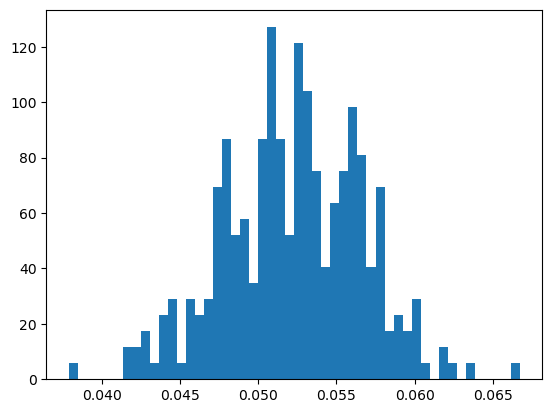

In [11]:
plt.hist(taus, bins=50, density=True)

In [42]:
print(taus.std(), taus.mean())

0.01298336662520404 0.06064148296593186


plt.hist(taus, bins=50, density=True)

In [37]:
print(taus.std(), taus.mean())

0.0047479424658271275 0.04925651302605211


In [12]:
def sigma_tau_plot(noises, nsim, sim_func, version):
    sigma_tau = []
    bias_tau = []

    for n in noises:
        auto = sim_func(n, nsim, version)
        sigma_tau.append(auto.std())
        bias_tau.append(auto.mean() - 0.054)
        print(n)

    return np.array(sigma_tau), np.array(bias_tau)

In [44]:
noises = np.arange(10,210,10, dtype=float)
noises = np.insert(noises, 0, 0.1)
sigma, bias = sigma_tau_plot(noises, 400, full_sky_wishart, wishart=False)

xQML
spec: ['EE', 'BB']
nbin: 7
Memset: 0.25 Gb 2 spec 7 bin 2 768 pix
Construct Pl: 0.2 sec
Construct S: 0.0 sec
Construct El (nl=14): 2.8 sec
Construct Wll (nl=14): 0.3 sec
Construct estimator: 3.8 sec
0.1
xQML
spec: ['EE', 'BB']
nbin: 7
Memset: 0.25 Gb 2 spec 7 bin 2 768 pix
Construct Pl: 0.2 sec
Construct S: 0.0 sec
Construct El (nl=14): 2.6 sec
Construct Wll (nl=14): 0.3 sec
Construct estimator: 3.6 sec
10.0
xQML
spec: ['EE', 'BB']
nbin: 7
Memset: 0.25 Gb 2 spec 7 bin 2 768 pix
Construct Pl: 0.2 sec
Construct S: 0.0 sec
Construct El (nl=14): 2.8 sec
Construct Wll (nl=14): 0.3 sec
Construct estimator: 3.8 sec
20.0
xQML
spec: ['EE', 'BB']
nbin: 7
Memset: 0.25 Gb 2 spec 7 bin 2 768 pix
Construct Pl: 0.2 sec
Construct S: 0.0 sec
Construct El (nl=14): 2.6 sec
Construct Wll (nl=14): 0.3 sec
Construct estimator: 3.5 sec
30.0
xQML
spec: ['EE', 'BB']
nbin: 7
Memset: 0.25 Gb 2 spec 7 bin 2 768 pix
Construct Pl: 0.2 sec
Construct S: 0.0 sec
Construct El (nl=14): 3.9 sec
Construct Wll (nl=14)

In [13]:
import pandas as pd
goal = pd.read_csv("goal_table.csv", names=['noise','sigma_tau'])

(5, 210)

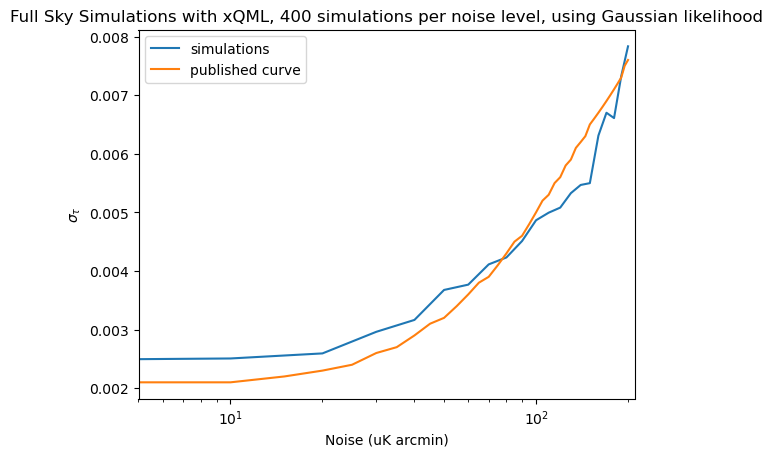

In [46]:
plt.semilogx(noises, sigma, label='simulations')
plt.semilogx(goal['noise'], goal['sigma_tau'], label='published curve')
plt.xlabel("Noise (uK arcmin)")
plt.ylabel(r'$\sigma_{\tau}$')
plt.title("Full Sky Simulations with xQML, 400 simulations per noise level, using Gaussian likelihood")
plt.legend()
plt.xlim(5,210)

(5, 210)

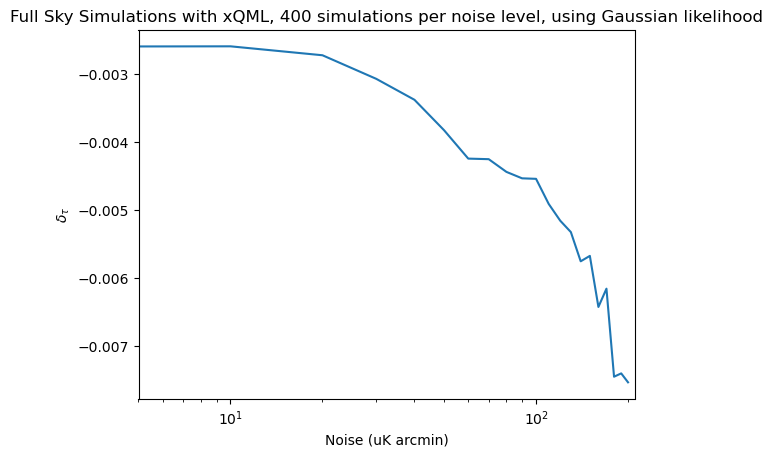

In [47]:
plt.semilogx(noises, bias, label='simulations')
plt.xlabel("Noise (uK arcmin)")
plt.ylabel(r'$\delta_{\tau}$')
plt.title("Full Sky Simulations with xQML, 400 simulations per noise level, using Gaussian likelihood")
plt.xlim(5,210)

In [48]:
noises = np.arange(10,210,10, dtype=float)
noises = np.insert(noises, 0, 0.1)
sigma_w, bias_w = sigma_tau_plot(noises, 400, full_sky_wishart, wishart=True)

xQML
spec: ['EE', 'BB']
nbin: 7
Memset: 0.25 Gb 2 spec 7 bin 2 768 pix
Construct Pl: 0.2 sec
Construct S: 0.0 sec
Construct El (nl=14): 3.7 sec
Construct Wll (nl=14): 0.3 sec
Construct estimator: 4.7 sec
0.1
xQML
spec: ['EE', 'BB']
nbin: 7
Memset: 0.25 Gb 2 spec 7 bin 2 768 pix
Construct Pl: 0.2 sec
Construct S: 0.0 sec
Construct El (nl=14): 3.0 sec
Construct Wll (nl=14): 0.2 sec
Construct estimator: 3.9 sec
10.0
xQML
spec: ['EE', 'BB']
nbin: 7
Memset: 0.25 Gb 2 spec 7 bin 2 768 pix
Construct Pl: 0.2 sec
Construct S: 0.0 sec
Construct El (nl=14): 2.6 sec
Construct Wll (nl=14): 0.2 sec
Construct estimator: 3.5 sec
20.0
xQML
spec: ['EE', 'BB']
nbin: 7
Memset: 0.25 Gb 2 spec 7 bin 2 768 pix
Construct Pl: 0.2 sec
Construct S: 0.0 sec
Construct El (nl=14): 2.7 sec
Construct Wll (nl=14): 0.3 sec
Construct estimator: 3.6 sec
30.0
xQML
spec: ['EE', 'BB']
nbin: 7
Memset: 0.25 Gb 2 spec 7 bin 2 768 pix
Construct Pl: 0.2 sec
Construct S: 0.0 sec
Construct El (nl=14): 2.8 sec
Construct Wll (nl=14)

In [14]:
noises = np.arange(10,210,10, dtype=float)
noises = np.insert(noises, 0, 0.1)
sigma_gc, bias_gc = sigma_tau_plot(noises, 400, full_sky_wishart, version=2)

xQML
spec: ['EE', 'BB']
nbin: 7
Memset: 0.25 Gb 2 spec 7 bin 2 768 pix
Construct Pl: 0.1 sec
Construct S: 0.0 sec
Construct El (nl=14): 3.0 sec
Construct Wll (nl=14): 0.3 sec
Construct estimator: 6.0 sec
0.1
xQML
spec: ['EE', 'BB']
nbin: 7
Memset: 0.25 Gb 2 spec 7 bin 2 768 pix
Construct Pl: 0.2 sec
Construct S: 0.0 sec
Construct El (nl=14): 2.7 sec
Construct Wll (nl=14): 0.3 sec
Construct estimator: 4.4 sec
10.0
xQML
spec: ['EE', 'BB']
nbin: 7
Memset: 0.25 Gb 2 spec 7 bin 2 768 pix
Construct Pl: 0.2 sec
Construct S: 0.0 sec
Construct El (nl=14): 2.1 sec
Construct Wll (nl=14): 0.3 sec
Construct estimator: 3.4 sec
20.0
xQML
spec: ['EE', 'BB']
nbin: 7
Memset: 0.25 Gb 2 spec 7 bin 2 768 pix
Construct Pl: 0.2 sec
Construct S: 0.0 sec
Construct El (nl=14): 3.0 sec
Construct Wll (nl=14): 0.3 sec
Construct estimator: 4.4 sec
30.0
xQML
spec: ['EE', 'BB']
nbin: 7
Memset: 0.25 Gb 2 spec 7 bin 2 768 pix
Construct Pl: 0.2 sec
Construct S: 0.0 sec
Construct El (nl=14): 2.9 sec
Construct Wll (nl=14)

(5, 210)

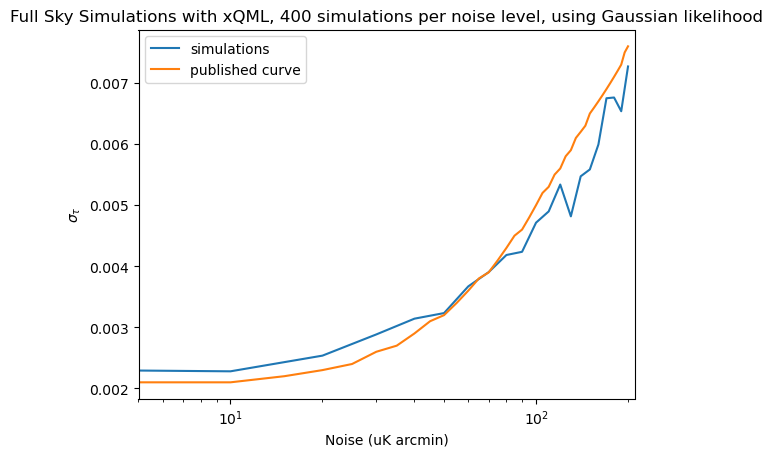

In [15]:
plt.semilogx(noises, sigma_gc, label='simulations')
plt.semilogx(goal['noise'], goal['sigma_tau'], label='published curve')
plt.xlabel("Noise (uK arcmin)")
plt.ylabel(r'$\sigma_{\tau}$')
plt.title("Full Sky Simulations with xQML, 400 simulations per noise level, using Gaussian likelihood")
plt.legend()
plt.xlim(5,210)

(5, 210)

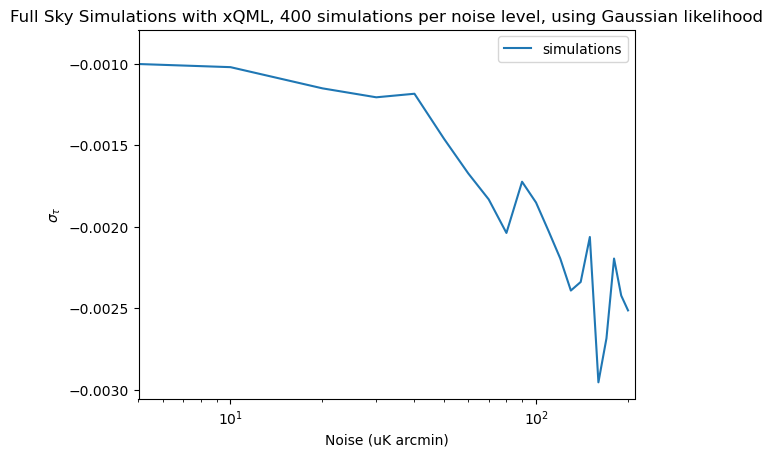

In [16]:
plt.semilogx(noises, bias_gc, label='simulations')
plt.xlabel("Noise (uK arcmin)")
plt.ylabel(r'$\sigma_{\tau}$')
plt.title("Full Sky Simulations with xQML, 400 simulations per noise level, using Gaussian likelihood")
plt.legend()
plt.xlim(5,210)

# error in title: these are actually supposed to be wishart likelihood

(5, 210)

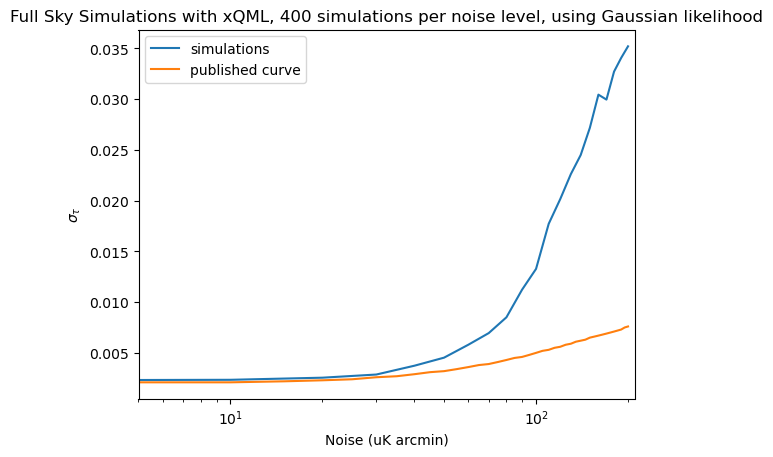

In [49]:
plt.semilogx(noises, sigma_w, label='simulations')
plt.semilogx(goal['noise'], goal['sigma_tau'], label='published curve')
plt.xlabel("Noise (uK arcmin)")
plt.ylabel(r'$\sigma_{\tau}$')
plt.title("Full Sky Simulations with xQML, 400 simulations per noise level, using Gaussian likelihood")
plt.legend()
plt.xlim(5,210)

(5, 210)

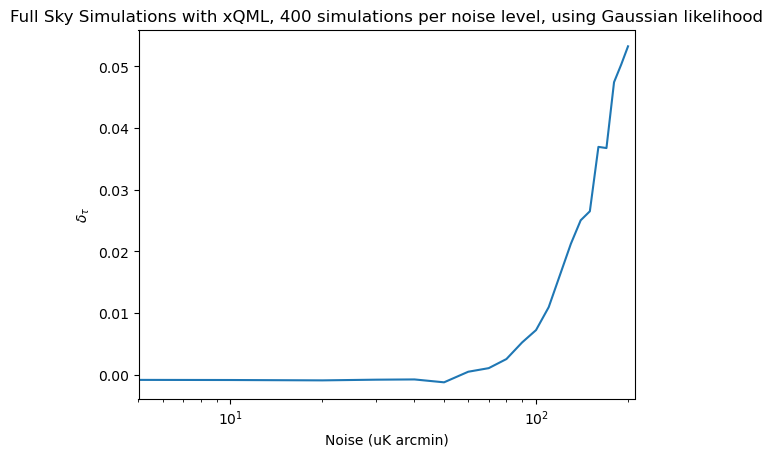

In [50]:
plt.semilogx(noises, bias_w, label='simulations')
plt.xlabel("Noise (uK arcmin)")
plt.ylabel(r'$\delta_{\tau}$')
plt.title("Full Sky Simulations with xQML, 400 simulations per noise level, using Gaussian likelihood")
plt.xlim(5,210)